## Parashikimi i shitjeve ditore

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_data, clean_data, add_columns
from src.forecasting import build_daily_series, validate_daily

sales, returns = clean_data(load_data())
sales = add_columns(sales)
returns = add_columns(returns)

Rreshta fillestare: 1,067,371
Dublikate:                                 hequr:    34335 | mbeten: 1,033,036
Anulime (ndahen te returns)                hequr:    19104 | mbeten: 1,013,932
Quantity <= 0                              hequr:     3393 | mbeten: 1,010,539
Price <= 0                                 hequr:     2626 | mbeten: 1,007,913
Kode te cilat nuk jane produkte            hequr:     4699 | mbeten: 1,003,214
Kodet e hequra (top 10):  {'POST': 1851, 'DOT': 1415, 'M': 846, 'C2': 267, 'ADJUST': 36, 'BANK CHARGES': 34, 'DCGS0058': 30, 'gift_0001_20': 26, 'gift_0001_30': 24, 'DCGSSGIRL': 23}
Rreshta te shitjes pas pastrimit: 1,003,214


In [2]:
last = sales["InvoiceDate"].max()
last_day = sales["Date"].max()
print("Fatura e fundit: ", last)
print("Te ardhurat e dites se fundit:", round(sales.loc[sales["Date"] == last_day, "Revenue"].sum()))
print("Mediana e te ardhurave ditore (ditet me shitje):", round(sales.groupby("Date")["Revenue"].sum().median()))

Fatura e fundit:  2011-12-09 12:50:00
Te ardhurat e dites se fundit: 198095
Mediana e te ardhurave ditore (ditet me shitje): 28180


In [3]:
daily = build_daily_series(sales, returns, drop_last_day=True)
validate_daily(daily)
print(daily.shape)
daily.head(10)


Kontrollet e serise ditore: OK
Dite me te ardhura neto negative: 3
(738, 5)


,revenue,orders,refunds,is_open,net_revenue
Date,,,,,
2009-12-01,52429.13,117,-1340.47,True,51088.66
2009-12-02,61873.10,115,-588.92,True,61284.18
2009-12-03,73025.12,124,-5944.86,True,67080.26
2009-12-04,39349.21,88,-386.52,True,38962.69
2009-12-05,9803.05,30,0.00,True,9803.05
2009-12-06,24285.02,74,-296.44,True,23988.58
2009-12-07,42923.68,101,-746.33,True,42177.35
2009-12-08,48694.71,105,-5774.09,True,42920.62
2009-12-09,38851.26,87,-219.54,True,38631.72


In [4]:
print(round(daily["revenue"].sum()), round(sales["Revenue"].sum()))

19444598 19642692


In [5]:
#ditet pa shitje
closed = daily[~daily["is_open"]]
print("Dite kalendarike:", len(daily))
print("Dite me shitje:", int(daily["is_open"].sum()))
print("Dite pa shitje:", len(closed))
print(closed.index.day_name().value_counts())

Dite kalendarike: 738
Dite me shitje: 603
Dite pa shitje: 135
Date
Saturday     104
Monday        11
Friday         7
Sunday         6
Thursday       3
Tuesday        2
Wednesday      2
Name: count, dtype: int64


In [6]:
run_id = daily["is_open"].ne(daily["is_open"].shift()).cumsum()
runs = (daily.reset_index().groupby(run_id.values).agg(
                nga=("Date", "min"),
                deri=("Date", "max"),
                dite=("Date", "size"),
                hapur=("is_open", "first")
            ))
runs[(~runs["hapur"]) & (runs["dite"] >= 3)]

,nga,deri,dite,hapur
6,2009-12-24,2010-01-03,11,False
32,2010-04-02,2010-04-05,4,False
114,2010-12-24,2011-01-03,11,False
146,2011-04-22,2011-04-25,4,False


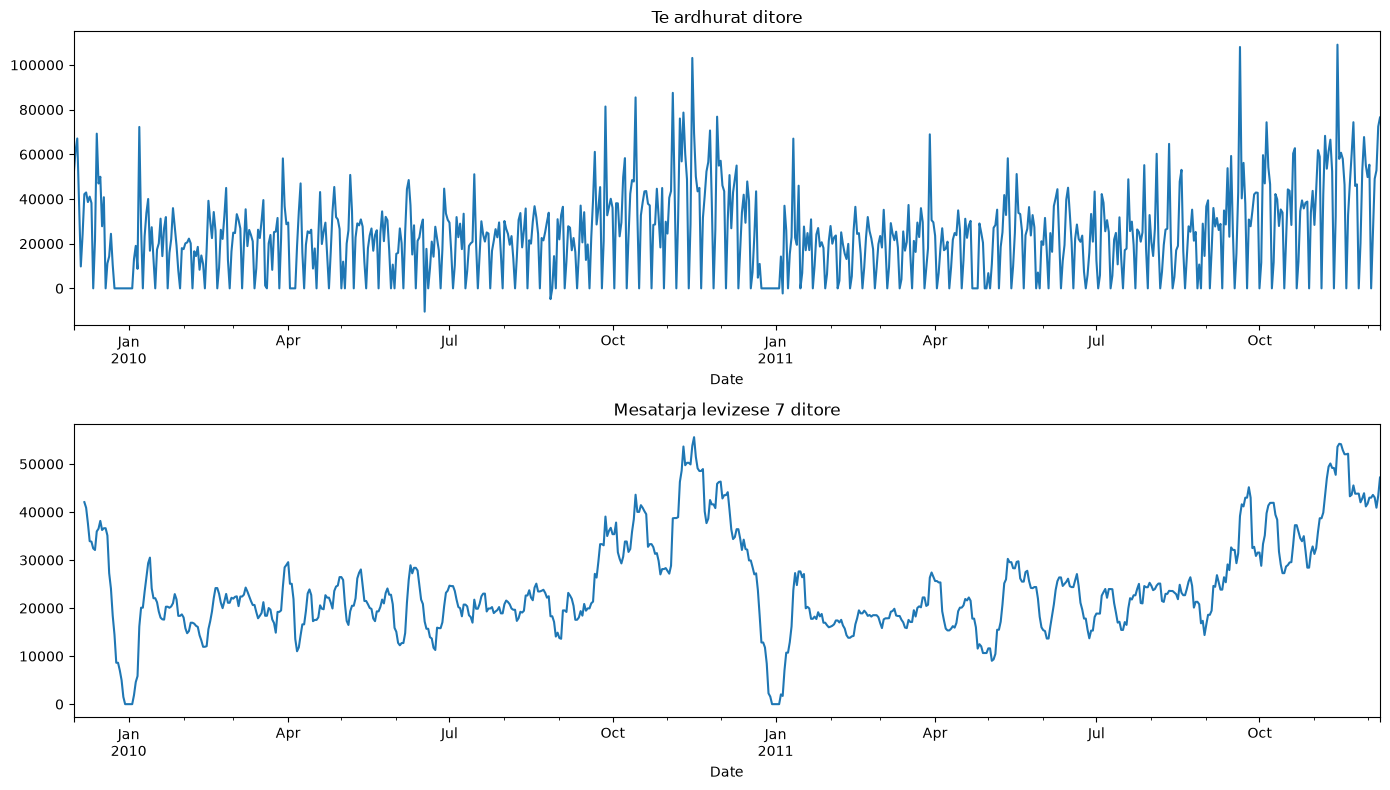

In [7]:
fig, axes = plt.subplots(2, 1 , figsize=(14, 8))
daily["net_revenue"].plot(ax=axes[0], title="Te ardhurat ditore")
daily["net_revenue"].rolling(7).mean().plot(ax=axes[1], title="Mesatarja levizese 7 ditore")
plt.tight_layout()
plt.show()

In [8]:
daily["weekday"] = daily.index.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print(daily.groupby("weekday")["net_revenue"].agg(["mean", "median"]).reindex(order).round(0))

open_days = daily[daily["is_open"]]
print(open_days["net_revenue"].describe().round(0))
open_days["net_revenue"].nlargest(5)

              mean   median
weekday                    
Monday     30017.0  26214.0
Tuesday    33265.0  28677.0
Wednesday  30227.0  27646.0
Thursday   35424.0  31798.0
Friday     26092.0  25116.0
Saturday      93.0      0.0
Sunday     16810.0  16613.0
count       603.0
mean      30102.0
std       16133.0
min      -10426.0
25%       19747.0
50%       26647.0
75%       37579.0
max      109070.0
Name: net_revenue, dtype: float64


Date
2011-11-14    109069.83
2011-09-20    108038.52
2010-11-15    103134.36
2010-11-04     87508.49
2010-10-14     85466.39
Name: net_revenue, dtype: float64

In [9]:
inv = sales.groupby(["Date", "Invoice"])["Revenue"].sum().reset_index()
open_days = daily[daily["is_open"]]

for d in open_days["revenue"].nlargest(6).index:
    day = inv[inv["Date"] == d].sort_values("Revenue", ascending=False)
    top = day.iloc[0]
    share = top["Revenue"] / day["Revenue"].sum() * 100
    print(d.date(), "| dita:", round(day["Revenue"].sum()), "| fatura me e madhe:", top["Invoice"], round(top["Revenue"]), f"({share:.0f}%)")

2011-11-14 | dita: 111349 | fatura me e madhe: 576365 50654 (45%)
2011-09-20 | dita: 108364 | fatura me e madhe: 567423 31698 (29%)
2010-11-15 | dita: 103336 | fatura me e madhe: 533027 49845 (48%)
2010-09-27 | dita: 102425 | fatura me e madhe: 524181 33168 (32%)
2011-01-18 | dita: 94365 | fatura me e madhe: 541431 77184 (82%)
2010-11-04 | dita: 88826 | fatura me e madhe: 530715 17022 (19%)


In [10]:
row = sales[sales["Date"] == "2011-12-09"].nlargest(1, "Revenue").iloc[0]
print(row[["Invoice", "InvoiceDate", "StockCode", "Description", "Quantity", "Price", "Customer ID", "Revenue"]])

returns[(returns["StockCode"] == row["StockCode"]) & (returns["Customer ID"] == row["Customer ID"])][["Invoice", "InvoiceDate", "Quantity", "Revenue"]]

Invoice                             581483
InvoiceDate            2011-12-09 09:15:00
StockCode                            23843
Description    PAPER CRAFT , LITTLE BIRDIE
Quantity                             80995
Price                                 2.08
Customer ID                          16446
Revenue                           168469.6
Name: 1001747, dtype: object


,Invoice,InvoiceDate,Quantity,Revenue
1065883,C581484,2011-12-09 09:27:00,-80995,-168469.6


In [11]:
print("Shitje:", round(sales["Revenue"].sum()), "| Anulime:", round(returns["Revenue"].sum()))
print("Anulimet si % e shitjeve:", round(-returns["Revenue"].sum() / sales["Revenue"].sum() * 100, 1))

Shitje: 19642692 | Anulime: -1462051
Anulimet si % e shitjeve: 7.4


In [12]:
for inv_no in ["581483", "541431"]:
    r = sales[sales["Invoice"] == inv_no].nlargest(1, "Revenue").iloc[0]
    m = returns[(returns["StockCode"] == r["StockCode"])
                & (returns["Customer ID"] == r["Customer ID"])
                & (returns["Quantity"] == -r["Quantity"])]
    print(inv_no, "|", r["InvoiceDate"], "| sasia", r["Quantity"], "| anulimi:", m[["Invoice", "InvoiceDate"]].to_dict("records"))

581483 | 2011-12-09 09:15:00 | sasia 80995 | anulimi: [{'Invoice': 'C581484', 'InvoiceDate': Timestamp('2011-12-09 09:27:00')}]
541431 | 2011-01-18 10:01:00 | sasia 74215 | anulimi: [{'Invoice': 'C541433', 'InvoiceDate': Timestamp('2011-01-18 10:17:00')}]


In [13]:
cmp = daily.loc[daily["is_open"], ["revenue", "refunds", "net_revenue"]]
cmp.sort_values("revenue", ascending=False).head(8).round(0)

,revenue,refunds,net_revenue
Date,,,
2011-11-14,111349.0,-2279.0,109070.0
2011-09-20,108364.0,-326.0,108039.0
2010-11-15,103336.0,-202.0,103134.0
2010-09-27,102425.0,-21034.0,81391.0
2011-01-18,94365.0,-77297.0,17067.0
2010-11-04,88826.0,-1318.0,87508.0
2010-10-14,86915.0,-1449.0,85466.0
2011-11-07,84150.0,-15881.0,68269.0


## Seria e shitjeve ditore

**Si u nderte**
- Seria ditore ka nje rresht per cdo dite kalendarike, nga 2009-12-01 deri 2011-12-08: 738 dite, nga te cilat 603 kane shitje dhe 135 jane pa shitje (18.3%).
- Per cdo dite ruhen: te ardhurat bruto te shitjeve (revenue), anulimet e dites (refunds, negative), te ardhurat neto (net_revenue = revenue + refunds), numri i faturave (orders) dhe nese ka pasur shitje (is_open).

**Problemi i porosive gjigante qe anulohen**
- Fatura 581483 (2011-12-09, ora 09:15) kishte 80,995 cope te nje produkti (PAPER CRAFT , LITTLE BIRDIE) me vlere 168,470 £, pra 85% e te ardhurave te asaj dite. Fatura C581484 e anuloi te njejten sasi 12 minuta me vone.
- Fatura 541431 (2011-01-18, ora 10:01) kishte 74,215 cope dhe peshonte 82% te te ardhurave te dites. Fatura C541433 e anuloi 16 minuta me vone.
- Mediana e sasise per rresht eshte 3 dhe 99.9% e rreshtave jane nen 500 cope, ndaj keto dy porosi jane me shume se 140 here mbi kete prag. Me shume gjase jane gabime regjistrimi qe u korrigjuan menjehere.
- Meqe anulimet ishin ndare te returns, keto porosi mbeten te shitjet dhe i fryne te ardhurat bruto te dites. Dita 2011-01-18 ka vetem 17,067 £ neto ne vend te 94,365 £ bruto.
- Anulimet gjithsej jane 1,462,051 £ kundrejt 19,642,692 £ shitje, pra 7.4% e vleres se shitjeve.
- Vendim: variabla qe do te parashikohet eshte net_revenue (shitje minus anulime te regjistruara ne te njejten dite). Keshtu porosite e anuluara menjehere neutralizohen vete, pa heqje me dore te diteve te vecanta.

**Bruto kundrejt neto per ditet me te larta**

| Data | Bruto (£) | Anulime (£) | Neto (£) |
|---|---|---|---|
| 2011-11-14 | 111,349 | -2,279 | 109,070 |
| 2011-09-20 | 108,364 | -326 | 108,039 |
| 2010-11-15 | 103,336 | -202 | 103,134 |
| 2010-09-27 | 102,425 | -21,034 | 81,391 |
| 2011-01-18 | 94,365 | -77,297 | 17,067 |
| 2010-11-04 | 88,826 | -1,318 | 87,508 |
| 2010-10-14 | 86,915 | -1,449 | 85,466 |
| 2011-11-07 | 84,150 | -15,881 | 68,269 |

- Shumica e diteve kane anulime shume te vogla, por disa kane ndikim te madh: 2011-01-18 humbet 82% te vleres, 2010-09-27 humbet 20.5% dhe 2011-11-07 humbet 18.9%.

**Dita e fundit**
- Dita 2011-12-09 u hoq nga seria. Fatura e fundit eshte ne ora 12:50, pra dita nuk ka mbaruar dhe nuk krahasohet me ditet e plota. Edhe pas anulimit te porosise gjigante, vlera e mbetur (rreth 29,600 £) eshte per vetem gjysmen e dites.

**Ditet pa shitje (135 nga 738, 18.3%)**
- Shumica jane te Shtunat: 104 nga 105 te Shtuna nuk kane shitje. Pra dyqani praktikisht nuk shet te Shtunave.
- Ditet pa shitje sipas dites se javes: e Shtune 104, e Hene 11, e Premte 7, e Diel 6, e Enjte 3, e Marte 2, e Merkure 2.
- Ka kater pushime te gjata: 2009-12-24 deri 2010-01-03 (11 dite), 2010-04-02 deri 2010-04-05 (4 dite), 2010-12-24 deri 2011-01-03 (11 dite) dhe 2011-04-22 deri 2011-04-25 (4 dite). Sipas datave, jane pushimet e Krishtlindjeve dhe te Pashkeve.
- Vendim: ditet pa shitje marrin revenue = 0, refunds = 0 dhe is_open = False, qe kalendari te mbetet i plote dhe lag_7 te jete gjithmone e njejta dite e javes.

**Te ardhurat neto sipas dites se javes** (mesatare dhe mediane, ne te gjitha ditet kalendarike)

| Dita | Mesatarja (£) | Mediana (£) |
|---|---|---|
| E Hene | 30,017 | 26,214 |
| E Marte | 33,265 | 28,677 |
| E Merkure | 30,227 | 27,646 |
| E Enjte | 35,424 | 31,798 |
| E Premte | 26,092 | 25,116 |
| E Shtune | 93 | 0 |
| E Diel | 16,810 | 16,613 |

- E Shtuna eshte praktikisht e mbyllur dhe e Diela shet rreth 47% te asaj qe shet e Enjtja (mesatare 16,810 £ kundrejt 35,424 £).
- Dita me e forte eshte e Enjtja (mesatare 35,424 £, mediane 31,798 £), e ndjekur nga e Marta (33,265 £). E Premtja eshte dita me e dobet e diteve te punes (mesatare 26,092 £, mediane 25,116 £).

**Te ardhurat neto ditore (ditet me shitje)**
- Ka 603 dite me shitje. Mediana eshte 26,647 £, mesatarja 30,102 £ dhe devijimi standard 16,133 £. Mesatarja eshte mbi median, pra shperndarja ka bisht te gjate djathtas (pak dite me shume shitje).
- Maksimumi eshte 109,070 £ (2011-11-14) dhe minimumi -10,426 £ (dite ku anulimet kalojne shitjet).
- Pese ditet me te larta jane 2011-11-14 (109,070 £), 2011-09-20 (108,039 £), 2010-11-15 (103,134 £), 2010-11-04 (87,508 £) dhe 2010-10-14 (85,466 £). Te gjitha bien ne periudhen shtator-nentor te dy viteve, pra ka nje kulm sezonal ne vjeshte.
- Mesatarja levizese 7-ditore tregon rritje drejt vjeshtes (shtator-nentor) dhe renie te forte ne fund te dhjetorit dhe fillim te janarit, gjate pushimit te fundvitit.

**Kufizime**
- Anulimet regjistrohen ne diten kur behen, jo ne diten e shitjes origjinale. Kur nje porosi anulohet disa dite me vone, shitja mbetet ne diten e saj dhe anulimi zbritet ne diten tjeter. Per kete arsye ka dite me te ardhura neto negative (minimumi eshte -10,426 £); numri i tyre eshte 3.

## Vecorit e modelit

In [14]:
from src.forecasting import features_for_dates, make_dataset, validate_features, FEATURES

raw_features = features_for_dates(daily)
validate_features(raw_features)

data = make_dataset(daily)
print(raw_features.shape, data.shape)
data.head()

Kontrollet e vecorive: OK
(738, 13) (724, 14)


,lag_1,lag_2,lag_7,lag_14,avg_7,avg_14,day_of_week,month,is_weekend,year_end_break,year_sin,year_cos,target,is_open
Date,,,,,,,,,,,,,,
2009-12-15,69246.73,21655.36,42920.62,51088.66,35961.197143,39008.082143,1,12,0,0,-0.275913,0.961183,46934.01,True
2009-12-16,46934.01,69246.73,38631.72,61284.18,36534.538571,38711.321429,2,12,0,0,-0.259338,0.965787,49945.87,True
2009-12-17,49945.87,46934.01,41060.74,67080.26,38150.845714,37901.442143,3,12,0,0,-0.242687,0.970105,27786.72,True
2009-12-18,27786.72,49945.87,38213.21,38962.69,36254.557143,35094.760714,4,12,0,0,-0.225964,0.974136,40788.20,True
2009-12-19,40788.20,27786.72,0.00,9803.05,36622.412857,35225.154286,5,12,1,0,-0.209174,0.977879,0.00,False


In [15]:
raw_features[["target", "lag_1", "lag_7", "avg_7"]].iloc[14:24].round(0)

,target,lag_1,lag_7,avg_7
Date,,,,
2009-12-15,46934.0,69247.0,42921.0,35961.0
2009-12-16,49946.0,46934.0,38632.0,36535.0
2009-12-17,27787.0,49946.0,41061.0,38151.0
2009-12-18,40788.0,27787.0,38213.0,36255.0
2009-12-19,0.0,40788.0,0.0,36622.0
2009-12-20,11140.0,0.0,21655.0,36622.0
2009-12-21,14279.0,11140.0,69247.0,35120.0
2009-12-22,24422.0,14279.0,46934.0,27268.0
2009-12-23,10493.0,24422.0,49946.0,24052.0


In [16]:
data.groupby("year_end_break")["target"].agg(["count", "mean"]).round(0)

,count,mean
year_end_break,,
0,702,25079.0
1,22,0.0


In [17]:
data.corr()["target"].drop("target").sort_values(ascending=False).round(2)

lag_7             0.63
is_open           0.63
lag_14            0.55
avg_7             0.45
lag_1             0.41
avg_14            0.41
month             0.30
year_cos          0.11
lag_2             0.10
year_end_break   -0.23
year_sin         -0.29
day_of_week      -0.42
is_weekend       -0.54
Name: target, dtype: float64

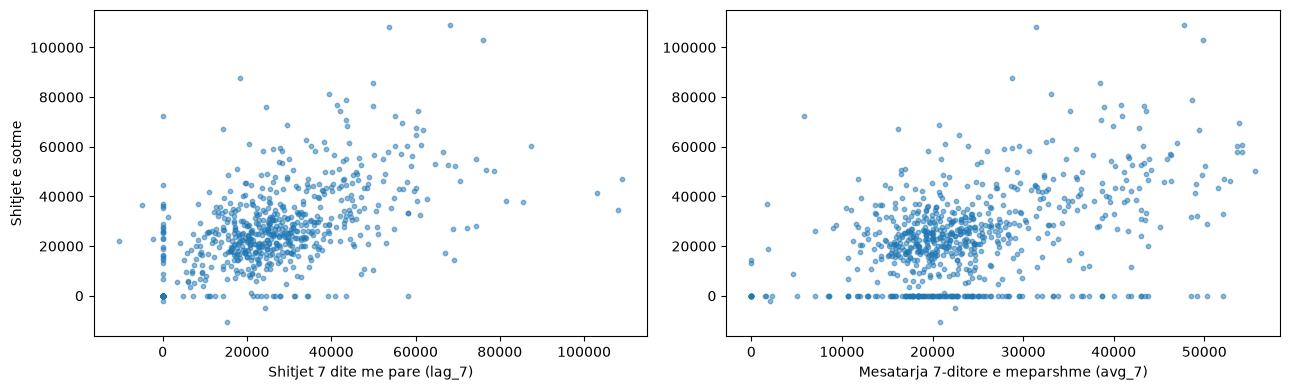

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(data["lag_7"], data["target"], s=10, alpha=0.5)
axes[0].set_xlabel("Shitjet 7 dite me pare (lag_7)")
axes[0].set_ylabel("Shitjet e sotme")
axes[1].scatter(data["avg_7"], data["target"], s=10, alpha=0.5)
axes[1].set_xlabel("Mesatarja 7-ditore e meparshme (avg_7)")
plt.tight_layout()
plt.show()

## Dita 14: Vecorite e modelit (src/forecasting.py)

**Cfare parashikojme:** te ardhurat neto ditore (net_revenue) te diteve te ardhshme.

**Vecorite (12)**
- Vlera te se kaluares: shitjet e dje (lag_1), e 2 diteve me pare (lag_2), e 7 diteve me pare (lag_7), e 14 diteve me pare (lag_14), mesatarja e 7 ditezve te fundit (avg_7) dhe e 14 diteve te fundit (avg_14).
- Kalendari: dita e javes, muaji, a eshte fundjave (is_weekend), a eshte pushimi i fundvitit 24 dhjetor - 3 janar (year_end_break), dhe dita e vitit si rreth (year_sin, year_cos), qe 31 dhjetori te jete afer 1 janarit.

**Pa rrjedhje te dhenash (data leakage)**
- Cdo vecori per diten D perdor vetem informacion para dites D. Mesataret fillojne me shift(1), qe dita e sotme te mos hyje ne to.
- Kontrolli automatik validate_features verifikon qe lag_1 dhe lag_7 jane vlerat e sakta te se kaluares, dhe qe avg_7 eshte mesatarja e 7 diteve para dites aktuale.
- year_end_break dhe vecorite e kalendarit dihen paraprakisht, ndaj nuk jane rrjedhje.

**Rezultati**
- Tabela e plote ka 738 rreshta, dhe pas heqjes se 14 diteve te para (qe nuk kane lag_14) mbeten 724 rreshta per model.
- Ne ditet e pushimit te fundvitit (22 dite) mesatarja e te ardhurave eshte 0£, kundrejt 25079£ ne ditet e tjera.
- Vecorite me korrelacion me te larte me te ardhurat e dites jane lag_7 (0.63) dhe lag_14 (0.55).

**Kufizime**
- Vecorite jane te thjeshta dhe nuk e dine kur fillojne pushimet e Pashkeve apo pushime te tjera te papritura.
- Kemi vetem dy sezone te fundvitit ne te dhena, qe e kufizon aftesine e modelit per te mesuar sezonalitetin.

## Modeli i pare dhe baselinet

In [19]:
from src.forecasting import train_and_test

result = train_and_test(daily)
tp = result.test_predictions
print("Trajnim:", result.train_size, "dite | Testim:", result.test_size, "dite")
print("Periudha e testimit:", tp.index.min().date(), "->", tp.index.max().date())
result.metrics.round(0)

Trajnim: 579 dite | Testim: 145 dite
Periudha e testimit: 2011-07-17 -> 2011-12-08


,MAE,RMSE,MAE_dite_me_shitje,RMSE_dite_me_shitje
Random Forest,8890.0,13631.0,10228.0,14626.0
Baseline: dje,19847.0,25581.0,17187.0,22661.0
Baseline: java e kaluar,11491.0,16914.0,13214.0,18119.0


In [20]:
print(round((tp["actual"] - tp["baseline_yesterday"]).abs().mean(), 0))
print(round(result.metrics.loc["Baseline: dje", "MAE"], 0))

19847.0
19847.0


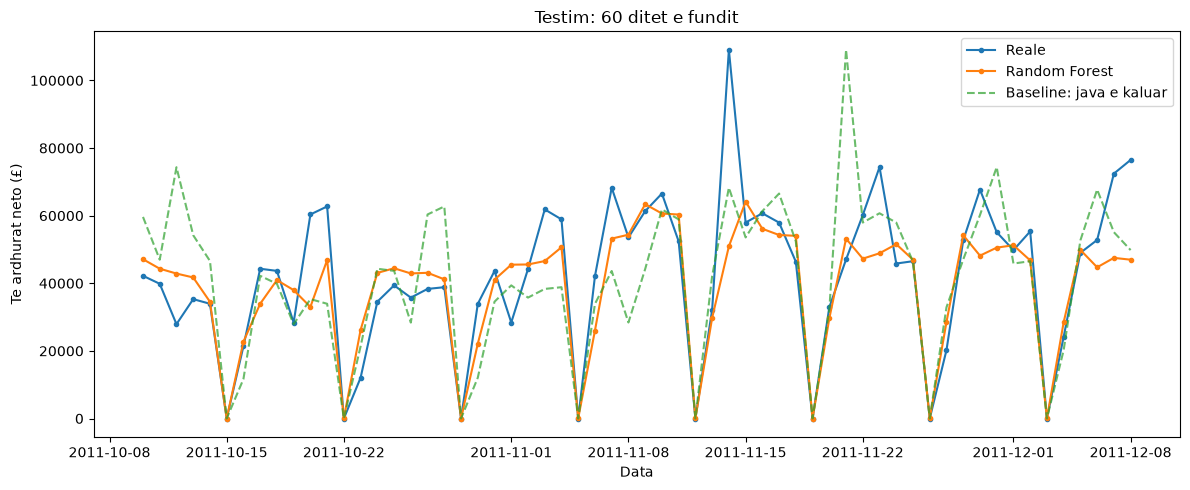

In [21]:
last = tp.tail(60)
plt.figure(figsize=(12, 5))
plt.plot(last.index, last["actual"], label="Reale", marker="o", markersize=3)
plt.plot(last.index, last["prediction"], label="Random Forest", marker="o", markersize=3)
plt.plot(last.index, last["baseline_week"], label="Baseline: java e kaluar", linestyle="--", alpha=0.7)
plt.title("Testim: 60 ditet e fundit")
plt.xlabel("Data")
plt.ylabel("Te ardhurat neto (£)")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
result.importance.round(3)

,feature,importance
6,day_of_week,0.227
4,avg_7,0.170
2,lag_7,0.164
5,avg_14,0.091
0,lag_1,0.079
8,is_weekend,0.073
11,year_cos,0.051
10,year_sin,0.049
3,lag_14,0.036
1,lag_2,0.026


## Modeli i pare (Random Forest) dhe baselinet

**Konfigurimi**
- Ndarje kronologjike: 80% e para e diteve per trajnim (579 dite, nga 2009-12-15 deri 2011-07-16) dhe 20% e fundit per testim (145 dite, nga 2011-07-17 deri 2011-12-08). 14 ditet e para te serise hiqen sepse nuk kane lag_14. Nuk perzihen rreshtat, qe modeli te mos shohe te ardhmen.
- Modeli: Random Forest (300 peme, max_depth = 12, min_samples_leaf = 3, random_state = 42), trajnuar mbi 12 vecori.
- Dy baseline: "dje" (vlera e dites se meparshme) dhe "java e kaluar" (vlera e te njejtes dite 7 dite me pare).
- Metrikat: MAE dhe RMSE (£), per te gjitha ditet dhe vetem per ditet me shitje (te shtunat dhe pushimet jane gjithmone zero dhe e ulin gabimin pa treguar aftesi te vertete).

**Rezultatet (ne testim)**

| Modeli | MAE (£) | RMSE (£) | MAE dite me shitje (£) | RMSE dite me shitje (£) |
|---|---|---|---|---|
| Random Forest | 8,890 | 13,631 | 10,228 | 14,626 |
| Baseline: dje | 19,847 | 25,581 | 17,187 | 22,661 |
| Baseline: java e kaluar | 11,491 | 16,914 | 13,214 | 18,119 |

Kontroll: MAE i baseline-it "dje", i llogaritur me dore nga parashikimet, eshte 19,847 £ dhe perputhet me tabelen.

**Vezhgime**
- Random Forest e mund qarte baseline-in "dje": MAE 8,890 kundrejt 19,847 £ (55.2% me i ulet), dhe vetem per ditet me shitje 10,228 kundrejt 17,187 £ (40.5% me i ulet). Baseline-i "dje" gabon shume rreth fundjaves: te shtunen e krahason me te premten (shume te ardhura) dhe te dielen e krahason me te shtunen (zero).
- Kundrejt baseline-it "java e kaluar" modeli eshte me i mire me 22.6%: MAE 8,890 kundrejt 11,491 £ per te gjitha ditet dhe 10,228 kundrejt 13,214 £ per ditet me shitje. RMSE eshte 13,631 kundrejt 16,914 £ (19.4% me i ulet).
- Gabimi i Random Forest ne ditet me shitje (10,228 £) eshte me i larte se ne te gjitha ditet (8,890 £), sepse te shtunat (zero) parashikohen lehte dhe e ulin mesataren. Prandaj matja me e ndershme eshte ajo per ditet me shitje. Mediana e te ardhurave neto ne ditet me shitje ne gjithe periudhen eshte 26,647 £, ndaj gabimi mesatar prej 10,228 £ eshte rreth 38% e saj. Modeli eshte i dobishem per te kuptuar nivelin e pergjithshem, por parashikimi i nje dite te vetme ka pasiguri te madhe.
- RMSE eshte rreth 1.5 here MAE (13,631 kundrejt 8,890 £), qe tregon se ka disa dite me gabime me te medha se mesatarja.

**Rendesia e vecorive (sipas modelit)**

| Vecoria | Rendesia |
|---|---|
| day_of_week | 0.227 |
| avg_7 | 0.170 |
| lag_7 | 0.164 |
| avg_14 | 0.091 |
| lag_1 | 0.079 |
| is_weekend | 0.073 |
| year_cos | 0.051 |
| year_sin | 0.049 |
| lag_14 | 0.036 |
| lag_2 | 0.026 |
| year_end_break | 0.026 |
| month | 0.007 |

- Dita e javes (day_of_week dhe is_weekend se bashku) shpjegon 30.0% te vendimeve te modelit, dhe vlerat e se kaluares (lag-et dhe mesataret) 56.6%. Vecorite e sezonit (year_sin, year_cos, month) japin 10.7%.
- year_end_break ka rendesi te ulet (0.026), sepse ne trajnim ka vetem dy pushime fundviti (rreth 22 dite) dhe ne testim asnje.
- Kujdes: rendesia tregon sa e ka perdorur modeli nje vecori, jo nese ajo shkakton shitjet. Vecoritë e ngjashme (avg_7, avg_14, lag_7) ndajne rendesine mes tyre. Interpretimin e plote do ta bej me permutation importance.

**Kufizime**
- Testimi mbulon korrikun-dhjetorin 2011 (vjeshta e ngarkuar) dhe ne trajnim ka vetem nje vjeshte (2010). Pyjet e rastit nuk parashikojne vlera me te larta se ato qe kane pare ne trajnim.
- Periudha e testimit nuk perfshin pushimin e fundvitit, ndaj year_end_break nuk vleresohet.
- Vleresimi eshte per parashikim nje dite perpara: vecorite e dites D perdorin vlerat reale te dites D-1. Per parashikim shtate-ditor lag-et do te mbushen me vlera te parashikuara dhe gabimi do te rritet.

## Krahasimi i modeleve

In [23]:
from src.forecasting import get_models
print(list(get_models()))

['Linear Regression', 'Random Forest', 'Gradient Boosting']


In [24]:
from src.forecasting import compare_models, cross_validate_models, get_models

metrics, view = compare_models(daily)
metrics.sort_values("MAE_dite_me_shitje").round(0)

,MAE,RMSE,MAE_dite_me_shitje,RMSE_dite_me_shitje
Random Forest,8890.0,13631.0,10228.0,14626.0
Gradient Boosting,9856.0,14508.0,11031.0,15552.0
Linear Regression,10888.0,14821.0,11092.0,15228.0
Baseline: java e kaluar,11491.0,16914.0,13214.0,18119.0
Baseline: dje,19847.0,25581.0,17187.0,22661.0


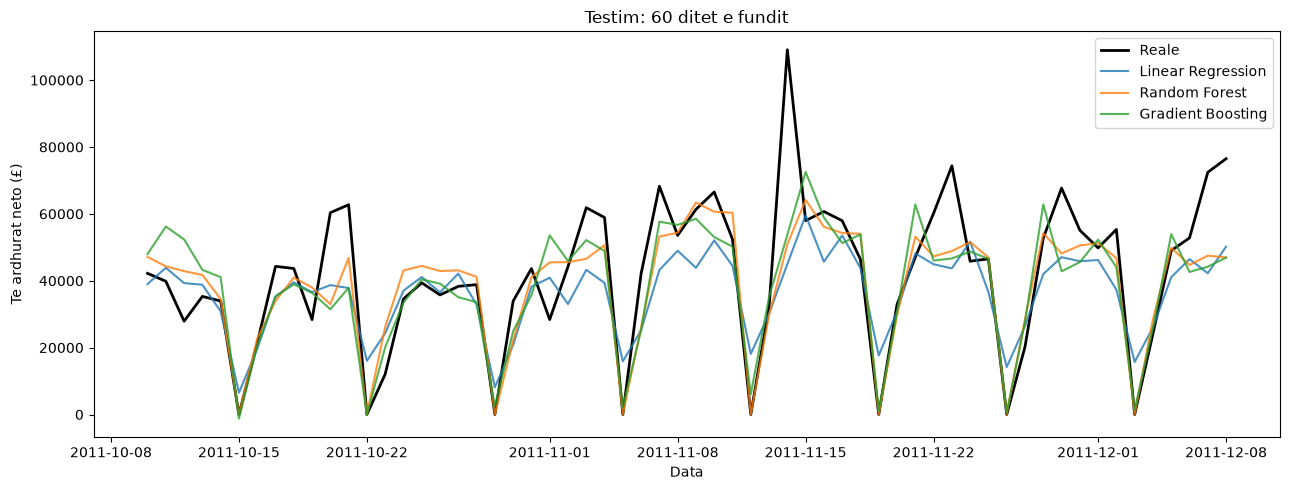

In [25]:
last = view.tail(60)
plt.figure(figsize=(13, 5))
plt.plot(last.index, last["actual"], label="Reale", color="black", linewidth=2)
for name in ["Linear Regression", "Random Forest", "Gradient Boosting"]:
    plt.plot(last.index, last[name], label=name, alpha=0.8)
plt.title("Testim: 60 ditet e fundit")
plt.xlabel("Data")
plt.ylabel("Te ardhurat neto (£)")
plt.legend()
plt.tight_layout()
plt.show()


In [26]:
cv = cross_validate_models(daily)
print(cv[["fold", "train_dite", "test_start", "test_end"]].drop_duplicates().to_string(index=False))

folds =cv.pivot_table(index="model", columns="fold", values="MAE_dite_me_shitje")
summary = folds.copy()
summary["mesatarja"] = folds.mean(axis=1)
summary["devijimi"] = folds.std(axis=1)
summary.sort_values("mesatarja").round(0)

 fold  train_dite test_start   test_end
    1         124 2010-04-18 2010-08-15
    2         244 2010-08-16 2010-12-13
    3         364 2010-12-14 2011-04-12
    4         484 2011-04-13 2011-08-10
    5         604 2011-08-11 2011-12-08


fold,1,2,3,4,5,mesatarja,devijimi
model,,,,,,,
Random Forest,6673.0,16452.0,7743.0,7817.0,10543.0,9846.0,3960.0
Gradient Boosting,7711.0,16667.0,8824.0,8932.0,11096.0,10646.0,3582.0
Linear Regression,10835.0,16870.0,7821.0,7769.0,11478.0,10955.0,3716.0
Baseline: java e kaluar,10636.0,14376.0,9524.0,10181.0,14101.0,11764.0,2296.0
Baseline: dje,11510.0,17173.0,11522.0,12957.0,17431.0,14118.0,2966.0


In [27]:
print(folds.idxmin())
folds.idxmin().value_counts()

fold
1              Random Forest
2    Baseline: java e kaluar
3              Random Forest
4          Linear Regression
5              Random Forest
dtype: str


Random Forest              3
Baseline: java e kaluar    1
Linear Regression          1
Name: count, dtype: int64

## Krahasimi i modeleve

**Modelet**
- Linear Regression (me one-hot per diten e javes, sepse numri 0-6 nuk eshte shkalle lineare).
- Random Forest (300 peme, max_depth = 12, min_samples_leaf = 3).
- Gradient Boosting (300 peme te cekta, max_depth = 3, learning_rate = 0.05, subsample = 0.8).
- Dy baseline: "dje" dhe "java e kaluar". Te gjitha modelet perdorin te njejtat 12 vecori dhe te njejten ndarje kronologjike.

**Rezultatet ne ndarjen 80/20 (testim 2011-07-17 deri 2011-12-08)**

| Modeli | MAE (£) | RMSE (£) | MAE dite me shitje (£) | RMSE dite me shitje (£) |
|---|---|---|---|---|
| Random Forest | 8,890 | 13,631 | 10,228 | 14,626 |
| Gradient Boosting | 9,856 | 14,508 | 11,031 | 15,552 |
| Linear Regression | 10,888 | 14,821 | 11,092 | 15,228 |
| Baseline: java e kaluar | 11,491 | 16,914 | 13,214 | 18,119 |
| Baseline: dje | 19,847 | 25,581 | 17,187 | 22,661 |

**Cross-validation me TimeSeriesSplit (5 folds)**

| Fold | Periudha e testimit | Dite trajnimi |
|---|---|---|
| 1 | 2010-04-18 deri 2010-08-15 | 124 |
| 2 | 2010-08-16 deri 2010-12-13 | 244 |
| 3 | 2010-12-14 deri 2011-04-12 | 364 |
| 4 | 2011-04-13 deri 2011-08-10 | 484 |
| 5 | 2011-08-11 deri 2011-12-08 | 604 |

MAE ne ditet me shitje (£):

| Modeli | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 | Mesatarja | Devijimi |
|---|---|---|---|---|---|---|---|
| Random Forest | 6,673 | 16,452 | 7,743 | 7,817 | 10,543 | 9,846 | 3,960 |
| Gradient Boosting | 7,711 | 16,667 | 8,824 | 8,932 | 11,096 | 10,646 | 3,582 |
| Linear Regression | 10,835 | 16,870 | 7,821 | 7,769 | 11,478 | 10,955 | 3,716 |
| Baseline: java e kaluar | 10,636 | 14,376 | 9,524 | 10,181 | 14,101 | 11,764 | 2,296 |
| Baseline: dje | 11,510 | 17,173 | 11,522 | 12,957 | 17,431 | 14,118 | 2,966 |

Modeli me i mire per fold: fold 1 Random Forest, fold 2 baseline "java e kaluar", fold 3 Random Forest, fold 4 Linear Regression, fold 5 Random Forest.

**Vezhgime**
- Ne ndarjen 80/20 Random Forest eshte me i miri: MAE 10,228 £ ne ditet me shitje, kundrejt 11,031 (Gradient Boosting, 7.9% me i larte), 11,092 (Linear Regression, 8.4% me i larte) dhe 13,214 te baseline-it "java e kaluar" (Random Forest eshte 22.6% me i ulet).
- Ne cross-validation Random Forest ka mesataren me te ulet (9,846 £) dhe fiton 3 nga 5 folds. Renditja e modeleve eshte e njejte me ate te ndarjes 80/20 (Random Forest, Gradient Boosting, Linear Regression, "java e kaluar", "dje"), pra perfundimi nuk varet nga nje periudhe e vetme.
- Random Forest eshte me i mire se Gradient Boosting ne te 5 folds dhe me i mire se Linear Regression ne 4 nga 5 (ne fold 4 Linear Regression fiton me vetem 48 £).
- Kundrejt baseline-it "java e kaluar" Random Forest fiton ne 4 nga 5 folds. Mesatarja e tij eshte 16.3% me e ulet (9,846 kundrejt 11,764 £), pak me pak se 22.6% i ndarjes 80/20.
- Fold 2 (2010-08-16 deri 2010-12-13) eshte me i veshtiri per te gjithe modelet (MAE 16,452 deri 17,173 £). Ne trajnimin e tij (244 dite, dhjetor 2009 deri gusht 2010) nuk ka asnje vjeshte, ndaj modeli nuk e ka pare kurre kulmin sezonal, dhe pemet nuk parashikojne vlera me te larta se ato qe kane pare ne trajnim. Vetem baseline-i "java e kaluar" (14,376 £), qe ndjek nivelin e fundit, e kalon modelin ne kete fold. Per ilustrim, pa fold 2 mesatarja e Random Forest do te ishte 8,194 £ kundrejt 11,111 £ te baseline-it. Rezultati zyrtar mbetet ai me te 5 folds.
- Devijimi i Random Forest (3,960 £) eshte me i larte se i baseline-it "java e kaluar" (2,296 £), kryesisht per shkak te fold 2.
- Ne fold 1, me vetem 124 dite trajnimi, Random Forest eshte prape me i miri (6,673 £), pra e meson shpejt ritmin javor.
- Linear Regression eshte modeli me i thjeshte dhe mesatarja e tij eshte vetem 11.3% mbi Random Forest (10,955 kundrejt 9,846 £). Ne fold 4 eshte me i miri. Pra pjesa me e madhe e sinjalit eshte e thjeshte: dita e javes dhe niveli i fundit i shitjeve.
- Gabimi mesatar i Random Forest (9,846 deri 10,228 £) eshte rreth 37-38% e medianes ditore te te ardhurave neto (26,647 £). Modeli kap ritmin javor dhe nivelin, por jo luhatjet e perditshme.
- Vendimi per modelin perfundimtar dhe rregullimi i hiperparametrave merren ne Diten 18. Kandidati kryesor eshte Random Forest.

**Kufizime**
- Pak te dhena (rreth dy vjet), ndaj te gjitha modelet kane pasiguri te madhe, sidomos ne folds e para, ku trajnimi eshte i shkurter dhe nuk ka vjeshte.
- Metrika "MAE dite me shitje" nuk perfshin ditet e pushimit, ndaj fold 3 (qe perfshin Krishtlindjet 2010) nuk tregon si i trajtuan modelet pushimin.
- Hiperparametrat jane te vendosur me dore dhe nuk jane optimizuar ende, ndaj renditja mund te ndryshoje pas rregullimit, sidomos per Gradient Boosting.
- Folds nuk jane te barabarta ne veshtiresi, sepse mbulojne stina te ndryshme.

## Parashikimi per 7 dite

In [28]:
from src.forecasting import train_final_model, predict_future

final_model = train_final_model(daily)
forecast = predict_future(daily, final_model, days=7)
print("Dita e fundit e te dhenave:", daily.index.max().date())
forecast

Dita e fundit e te dhenave: 2011-12-08


,day,forecast
date,,
2011-12-09,Friday,55448.0
2011-12-10,Saturday,0.0
2011-12-11,Sunday,23127.0
2011-12-12,Monday,52469.0
2011-12-13,Tuesday,52205.0
2011-12-14,Wednesday,53616.0
2011-12-15,Thursday,52769.0


U ruajt grafiku: C:\Users\Admin\Desktop\online-retail-customer-analytics\reports\figures\forecast_next_7_days.png


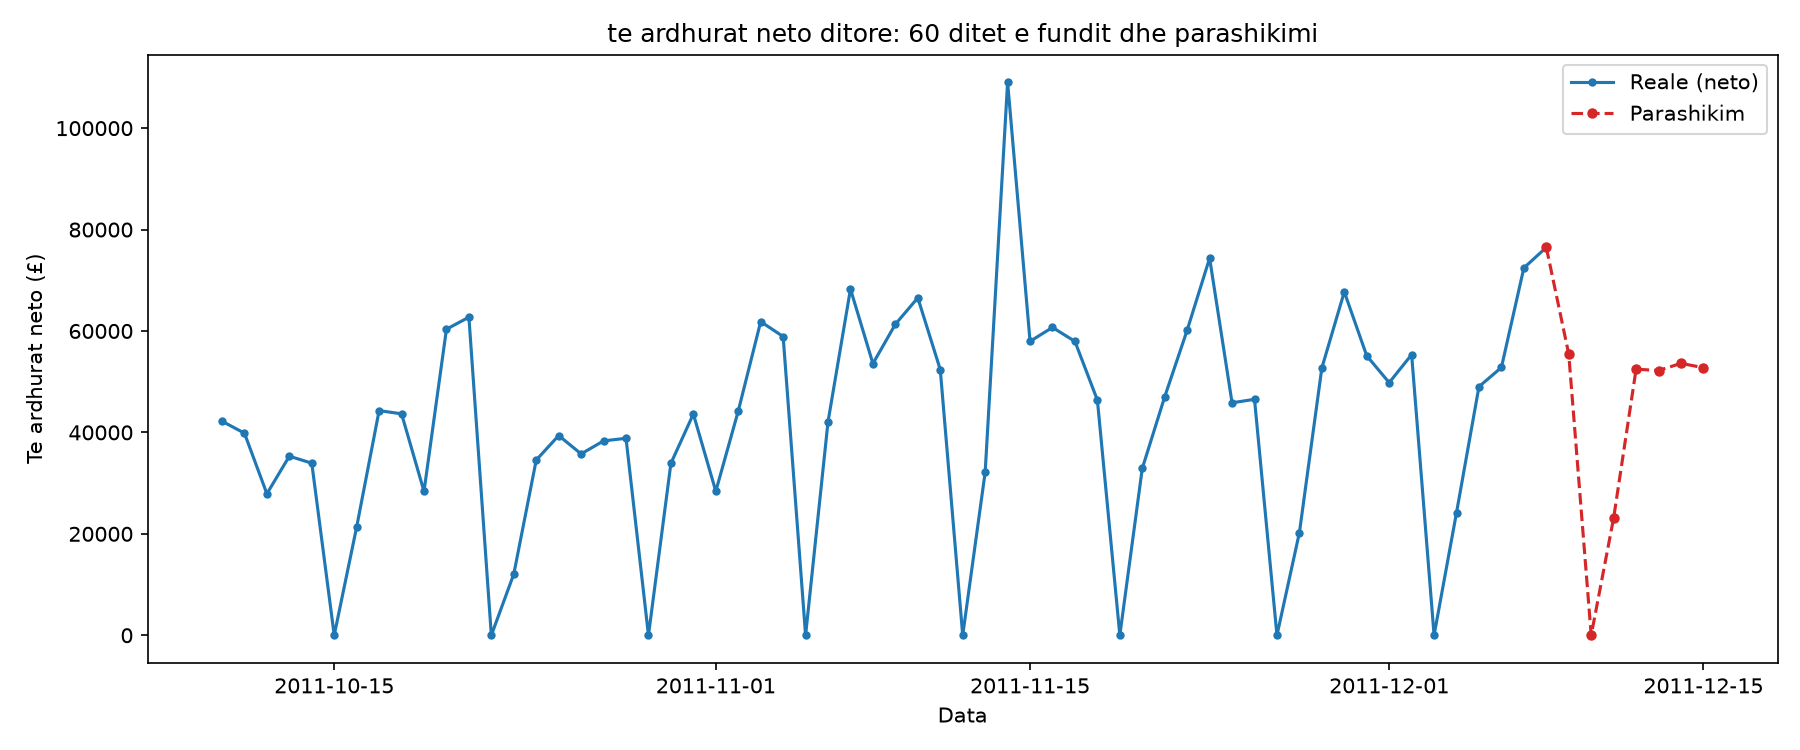

In [29]:
from IPython.display import Image
from src.forecasting import save_forecast_figure

save_forecast_figure(daily, forecast)
Image(filename="../reports/figures/forecast_next_7_days.png")

In [30]:
from src.forecasting import backtest_horizons, horizon_summary

hz = backtest_horizons(daily)
print(hz["origin"].nunique(), "origjina,", len(hz), "parashikime")
summary = horizon_summary(hz)
summary.round(0)

139 origjina, 973 parashikime


,MAE_modeli,MAE_baseline_java,MAE_modeli_dite_me_shitje,MAE_baseline_dite_me_shitje
h,,,,
1,8578.0,11509.0,9820.0,13210.0
2,8496.0,11426.0,9776.0,13225.0
3,8737.0,11425.0,10064.0,13223.0
4,8581.0,11279.0,9881.0,13051.0
5,8801.0,11279.0,10135.0,13051.0
6,9043.0,11390.0,10427.0,13182.0
7,9170.0,11538.0,10577.0,13355.0


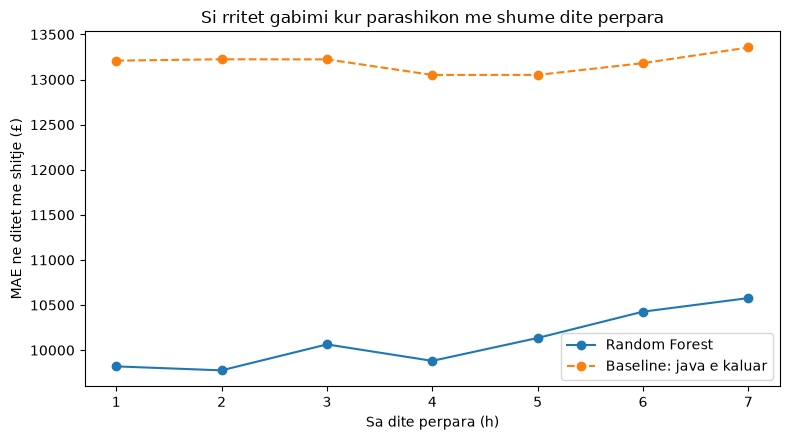

In [31]:
from src.forecasting import FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(summary.index, summary["MAE_modeli_dite_me_shitje"], marker="o", label="Random Forest")
ax.plot(summary.index, summary["MAE_baseline_dite_me_shitje"], marker="o", linestyle="--", label="Baseline: java e kaluar")
ax.set_xlabel("Sa dite perpara (h)")
ax.set_ylabel("MAE ne ditet me shitje (£)")
ax.set_title("Si rritet gabimi kur parashikon me shume dite perpara")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "horizon_error.png", dpi=150)
plt.show()

In [32]:
tot = hz.groupby("origin").agg(actual=("actual", "sum"), prediction=("prediction", "sum"))
tot["gabim"] = (tot["actual"] - tot["prediction"]).abs()
print(round(tot["gabim"].mean()), round(tot["actual"].mean()))

36338 230353


## Parashikimi per 7 dite

**Metoda**
- Modeli perfundimtar eshte Random Forest i rregulluar (n_estimators = 200, max_depth = 6, min_samples_leaf = 1, max_features = 0.4, shih Diten 18), trajnuar mbi te gjitha ditet e disponueshme (724 dite pas heqjes se 14 diteve te para).
- Parashikimi eshte rekursiv: parashikohet dita 1, vlera e saj futet ne seri sikur te ishte e vertete, dhe perdoret per te llogaritur vecorite e dites 2, e keshtu me radhe deri ne 7 dite. Vecorite jane llogaritur nga i njejti kod si ne trajnim.
- Parashikimet jane per 2011-12-09 deri 2011-12-15, pra 7 ditet pas fundit te te dhenave (2011-12-08). Per keto dite nuk kemi vlera te verteta per krahasim.

**Parashikimi**

| Data | Dita | Parashikimi (£) |
|---|---|---|
| 2011-12-09 | E Premte | 55448.0 |
| 2011-12-10 | E Shtune | 0.0 |
| 2011-12-11 | E Diel | 23127.0 |
| 2011-12-12 | E Hene | 52469.0 |
| 2011-12-13 | E Marte | 52205.0 |
| 2011-12-14 | E Merkure | 53616.0 |
| 2011-12-15 | E Enjte | 52769.0 |


**Si rritet gabimi me horizontin (139 origjina ne periudhen e testimit, 973 parashikime)**

| h (dite perpara) | MAE modeli (£) | MAE baseline "java e kaluar" (£) |
|---|---|---|
| 1 | 9,820 | 13,210 |
| 2 | 9,776 | 13,225 |
| 3 | 10,064 | 13,223 |
| 4 | 9,881 | 13,051 |
| 5 | 10,135 | 13,051 |
| 6 | 10,427 | 13,182 |
| 7 | 10,577 | 13,355 |

(MAE ne ditet me shitje.)

**Vezhgime**
- Gabimi i parashikimit 1 dite perpara eshte 9,820 £ dhe per 7 dite perpara 10,577 £, pra rritet me 7.7%. Rritja nuk eshte e barabarte: h = 2 eshte pak me i ulet se h = 1 dhe h = 4 pak me i ulet se h = 3 (dallime prej disa dhjetera £, qe jane zhurme), ndersa rritja me e dukshme eshte nga h = 5 ne h = 6 (+292 £).
- Modeli mbetet nen baseline-in "java e kaluar" per te gjithe horizontet. Dallimi eshte 3,390 £ (25.7%) ne h = 1 dhe 2,778 £ (20.8%) ne h = 7, pra avantazhi ngushtohet pak por nuk zhduket.
- Baseline-i mbetet pothuajse konstant (rreth 13,050-13,350 £), sepse vlera e se njejtes dite javen e kaluar eshte gjithmone e njohur nga origjina e parashikimit.
- Rritja e gabimit vjen nga fakti qe vecorite lag_1, lag_2 dhe avg_7 per ditet e mbrapshme mbushen me parashikime, jo me vlera te verteta. Vecorite lag_7 dhe lag_14 mbeten te verteta per te gjithe horizontet deri ne 7 dite.


**Kufizime**
- Parashikimi rekursiv grumbullon gabime, ndaj nuk rekomandohet pertej 7-14 diteve.
- Nuk ka interval besimi: pasiguria vleresohet vetem nga MAE historike.
- Modeli nuk e di per ngjarje te jashtme (pushime te papritura, fushata, porosi te medha). Dhjetori ka vetem dy shembuj ne trajnim, dhe pushimi i fundvitit (nga 24 dhjetori) eshte jashte horizontit te kesaj jave.
- Parametrat e modelit u zgjodhen nga 30 kombinime dhe permiresimi ndaj default eshte i moderuar (2.6% ne testim).

## Tuning i Random Forest

In [33]:
from src.forecasting import tune_random_forest, compare_tuned

search, default_scores = tune_random_forest(daily)
print("Parametrat me te mire:", search.best_params_)
print("MAE ne CV (tuned):  ", round(-search.best_score_))
print("MAE ne CV (default):", round(default_scores.mean()))

Parametrat me te mire: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.4, 'max_depth': 6}
MAE ne CV (tuned):   8030
MAE ne CV (default): 8403


In [34]:
res = pd.DataFrame(search.cv_results_)
cols = ["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
        "param_max_features", "mean_test_score", "std_test_score"]
top = res.sort_values("rank_test_score")[cols].head(10).copy()
top["MAE_mesatar"] = -top["mean_test_score"]
top = top.drop(columns="mean_test_score").rename(columns={"std_test_score": "devijimi"})
top.round({"MAE_mesatar": 0, "devijimi": 0})

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,devijimi,MAE_mesatar
17,200,6,1,0.4,2651.0,8030.0
14,200,4,2,0.8,2668.0,8045.0
1,200,6,2,0.4,2697.0,8055.0
23,300,4,1,1.0,2689.0,8066.0
9,300,8,2,0.4,2635.0,8118.0
2,200,8,1,0.8,2571.0,8141.0
16,300,16,2,0.6,2637.0,8155.0
12,300,8,1,1.0,2638.0,8193.0
24,300,12,1,0.8,2496.0,8204.0
5,500,10,2,1.0,2810.0,8319.0


In [35]:
fold_cols = [f"split{i}_test_score" for i in range(4)]
tuned_folds = -res.loc[search.best_index_, fold_cols].astype(float).to_numpy()

pd.DataFrame(
    {"default": default_scores, "tuned": tuned_folds},
    index=[f"fold {i}" for i in range(1, 5)],
).round(0)

,default,tuned
fold 1,6302.0,6383.0
fold 2,13459.0,12591.0
fold 3,6558.0,6149.0
fold 4,7294.0,6998.0


In [36]:
metrics, view = compare_tuned(daily, search.best_estimator_)
metrics.round(0)

,MAE,RMSE,MAE_dite_me_shitje,RMSE_dite_me_shitje
Random Forest (default),8890.0,13631.0,10228.0,14626.0
Random Forest (tuned),8686.0,13440.0,9963.0,14403.0
Baseline: java e kaluar,11491.0,16914.0,13214.0,18119.0


In [38]:
m = metrics["MAE_dite_me_shitje"]
print("Tuned kundrejt default (MAE ne ditet me shitje):",
      round((m["Random Forest (tuned)"] / m["Random Forest (default)"] - 1) * 100, 1), "%")

Tuned kundrejt default (MAE ne ditet me shitje): -2.6 %


## Tuning i Random Forest

**Metoda**
- RandomizedSearchCV: 30 kombinime te rastit nga 432 te mundshme (n_estimators, max_depth, min_samples_leaf, max_features), te vleresuara me TimeSeriesSplit (4 folds) vetem mbi pjesen e trajnimit (579 dite).
- Pjesa e testimit (145 dite, 2011-07-17 deri 2011-12-08) nuk u perdor per zgjedhjen e parametrave: u perdor vetem nje here, ne fund, per krahasimin.
- Metrika e zgjedhjes: MAE.

**Parametrat**

| Parametri | Default | Tuned |
|---|---|---|
| n_estimators | 300 | 200 |
| max_depth | 12 | 6 |
| min_samples_leaf | 3 | 1 |
| max_features | 1.0 (te gjitha vecorite) | 0.4 |

**Rezultatet ne cross-validation (MAE ne trajnim, 4 folds)**

| Modeli | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Mesatarja |
|---|---|---|---|---|---|
| Default | 6,302 | 13,459 | 6,558 | 7,294 | 8,403 |
| Tuned | 6,383 | 12,591 | 6,149 | 6,998 | 8,030 |

**Rezultatet ne testim**

| Modeli | MAE (£) | RMSE (£) | MAE dite me shitje (£) | RMSE dite me shitje (£) |
|---|---|---|---|---|
| Random Forest (default) | 8,890 | 13,631 | 10,228 | 14,626 |
| Random Forest (tuned) | 8,686 | 13,440 | 9,963 | 14,403 |
| Baseline: java e kaluar | 11,491 | 16,914 | 13,214 | 18,119 |

**Vezhgime**
- Ne cross-validation tuned ka MAE mesatare 8,030 £ kundrejt 8,403 £ te default (4.4% me i ulet). Fiton ne 3 nga 4 folds (fold 2: 6.4%, fold 3: 6.2%, fold 4: 4.1%) dhe humbet pak ne fold 1 (81 £, 1.3%), ku trajnimi ka vetem rreth 119 dite.
- Dhjete kombinimet me te mira kane MAE nga 8,030 deri 8,319 £, dhe te gjitha jane me te mira se default (8,403 £). Dallimi mes te parit dhe te dhjetit eshte vetem 289 £, shume me i vogel se devijimi mes folds (rreth 2,500-2,800 £, qe reflekton veshtiresine e ndryshme te periudhave). Pra renditja mes tyre nuk eshte e besueshme dhe nuk ka nje kombinim magjik, por drejtimi i pergjithshem eshte i qarte.
- Kombinimet me te mira kane peme me te cekta dhe me te ndryshme: 7 nga 10 kane max_depth deri ne 8, te 10 kane min_samples_leaf 1 ose 2 (default ka 3), dhe 7 nga 10 perdorin vetem nje pjese te vecorive ne cdo ndarje (max_features nen 1.0). Me vetem rreth 580 dite trajnimi, modelet me te thjeshta pergjithesojne pak me mire.
- Ne testimin e paprekur tuned eshte 2.6% me i mire se default ne MAE per ditet me shitje (9,963 kundrejt 10,228 £), 2.3% ne MAE per te gjitha ditet (8,686 kundrejt 8,890 £), dhe vetem rreth 1.4-1.5% ne RMSE (13,440 kundrejt 13,631 £ dhe 14,403 kundrejt 14,626 £). Permiresimi ne RMSE eshte me i vogel, qe tregon se gabimet e medha mbeten pothuajse te njejta. Kundrejt baseline-it "java e kaluar" modeli i rregulluar eshte 24.6% me i mire ne ditet me shitje (kundrejt 22.6% te default).
- **Vendimi:** pranoj modelin e rregulluar, sepse permiresimi shfaqet ne CV (4.4%), ne 3 nga 4 folds dhe ne testimin e paprekur (2.6%). Permiresimi eshte i moderuar, jo i madh.
- Perfundim: gabimi kufizohet kryesisht nga sasia e vogel e te dhenave (rreth dy vite) dhe nga zhurma ditore, jo nga hiperparametrat.

**Kufizime**
- 30 kombinime nga 432 nuk e kerkojne hapesiren e plote, dhe kombinimi me i mire ne CV mund te jete me fat per ato folds.
- Foldi 1 trajnon vetem mbi rreth 119 dite dhe foldi 2 (gusht-nentor 2010) nuk ka vjeshte te meparshme, ndaj rezultatet e tyre jane me te zhurmshme.
- Tuning-u u be vetem per Random Forest. Krahasimi i modeleve ne Diten 16 u be me parametrat e paracaktuar te te tre modeleve.
- Permiresimi eshte vleresuar ne nje periudhe testimi te vetme (vjeshta 2011).